# VTaC deep-learning starter

Ventricular tachycardia alarm records from ICU monitors, PhysioNet version 1.0.

**Download the waveforms (about 2.7 GB zipped, 4 GB unpacked):**

- Project page: https://physionet.org/content/vtac/1.0/
- ZIP: https://physionet.org/content/vtac/get-zip/1.0/
- DOI: https://doi.org/10.13026/8td2-g363

Unpack the ZIP into `vtac/data/` so `waveforms/` sits next to the label CSVs. This notebook downloads only the label and split tables, then trains a small 1D CNN on synthetic 10-second windows with the same shape as the paper's realtime inputs. When real WFDB files are present it loads one record with `wfdb`.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import wfdb

print("torch", torch.__version__)
print("wfdb", wfdb.__version__)
print("cuda", torch.cuda.is_available())

def find_root() -> Path:
    start = Path.cwd().resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "notebooks" / "vtac_deep_learning.ipynb").is_file():
            return candidate
    raise FileNotFoundError(f"VTaC project root not found from {start}")

ROOT = find_root()
DATA = ROOT / "data"
META = DATA / "metadata"
META.mkdir(parents=True, exist_ok=True)
DATA, META

torch 2.14.1+cpu
wfdb 4.3.1
cuda False


(PosixPath('/workspace/vtac/data'), PosixPath('/workspace/vtac/data/metadata'))

## Labels and the published split

`decision` is the adjudicated expert label (`True` = true VT alarm, `False` = false alarm). `benchmark_data_split.csv` is the train / validation / test split used in the paper.

In [2]:
PHYSIONET = "https://physionet.org/files/vtac/1.0"
for name in ("event_labels.csv", "benchmark_data_split.csv"):
    dest = META / name
    unpacked = DATA / name
    if dest.exists():
        continue
    if unpacked.exists():
        dest.write_bytes(unpacked.read_bytes())
        continue
    urllib.request.urlretrieve(f"{PHYSIONET}/{name}?download", dest)
    print("downloaded", dest)

labels = pd.read_csv(META / "event_labels.csv")
splits = pd.read_csv(META / "benchmark_data_split.csv")
events = labels.merge(splits, on=["record", "event"], how="inner")
# Recent pandas parses the True/False column as booleans.
events["decision"] = [
    "True" if (value is True or str(value).strip().lower() == "true") else "False"
    for value in events["decision"]
]
events["y"] = (events["decision"] == "True").astype(int)

print(f"{len(events):,} events")
print(events["decision"].value_counts())
print(events.groupby(["split", "decision"]).size().unstack(fill_value=0))
events.head()

downloaded /workspace/vtac/data/metadata/event_labels.csv


downloaded /workspace/vtac/data/metadata/benchmark_data_split.csv
5,037 events
decision
False    3596
True     1441
Name: count, dtype: int64
decision  False  True
split                
test        345   137
train      2897  1163
val         354   141


,record,event,decision,split,y
0,003c13,003c13_0115,False,train,0
1,003c13,003c13_0126,False,train,0
2,004bad,004bad_0015,False,train,0
3,004bad,004bad_1115,False,train,0
4,004bad,004bad_1426,False,train,0


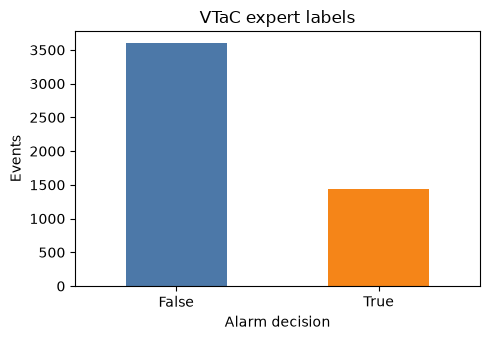

True-alarm rate: 28.6%


In [3]:
counts = events["decision"].value_counts().reindex(["False", "True"])
fig, ax = plt.subplots(figsize=(5, 3.5))
counts.plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518"], rot=0)
ax.set_title("VTaC expert labels")
ax.set_xlabel("Alarm decision")
ax.set_ylabel("Events")
fig.tight_layout()
plt.show()
print(f"True-alarm rate: {events['y'].mean():.1%}")

## Model input used by the paper

Each waveform is 6 minutes at 250 Hz (90,000 samples). The alarm starts at 5 minutes. Realtime models in the official code keep the last 10 seconds before that onset: `signal[:, :, 72500:75000]`, shape `(batch, 4, 2500)`.

The cell below builds a small 1D CNN for that window and fits it on synthetic traces. It checks that training runs. It does not score the VTaC test set, because the waveform archive is downloaded separately.

In [4]:
FS = 250
PRE_ALARM_SECONDS = 10
WINDOW = PRE_ALARM_SECONDS * FS  # 2500 samples
N_CHANNELS = 4  # ECG, ECG, PPG/PLETH, ABP

class VTAlarmCNN(nn.Module):
    """Binary classifier for a 10-second, 4-channel window."""

    def __init__(self, channels=N_CHANNELS):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(channels, 16, kernel_size=25, stride=5, padding=12),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=15, stride=5, padding=7),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.classifier = nn.Linear(32, 1)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1)).squeeze(-1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = VTAlarmCNN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"{model.__class__.__name__}: {n_params:,} parameters on {device}")

generator = torch.Generator().manual_seed(0)
x = torch.randn(128, N_CHANNELS, WINDOW, generator=generator)
y = torch.randint(0, 2, (128,), generator=generator, dtype=torch.float32)
true_rate = float(events["y"].mean())
pos_weight = torch.tensor([(1 - true_rate) / true_rate], device=device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

model.train()
losses = []
for epoch in range(1, 6):
    optimizer.zero_grad()
    logits = model(x.to(device))
    loss = loss_fn(logits, y.to(device))
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    print(f"epoch {epoch}: loss {loss.item():.4f}")

assert losses[-1] < losses[0], "synthetic training loss did not decrease"
print("training loop ok")

VTAlarmCNN: 9,457 parameters on cpu


epoch 1: loss 1.1916


epoch 2: loss 1.1781


epoch 3: loss 1.1652


epoch 4: loss 1.1528


epoch 5: loss 1.1407
training loop ok


## Real waveforms, once the ZIP is unpacked

Looks for `*.hea` files under `vtac/data/`. If none are there yet, it prints the download link and stops this cell cleanly.

In [5]:
headers = sorted(DATA.rglob("*.hea"))
print(f"WFDB headers found: {len(headers)}")
if not headers:
    print("No waveforms unpacked yet.")
    print("Download https://physionet.org/content/vtac/get-zip/1.0/")
    print("Unzip into", DATA.resolve())
else:
    header = headers[0]
    record = wfdb.rdrecord(str(header.with_suffix("")))
    print(header)
    print("signals", record.sig_name)
    print("fs", record.fs, "samples", record.sig_len)
    shown = min(record.sig_len, FS * 10)
    fig, axes = plt.subplots(record.n_sig, 1, figsize=(10, 2 * record.n_sig), sharex=True)
    if record.n_sig == 1:
        axes = [axes]
    time = [i / record.fs for i in range(shown)]
    for axis, name, signal in zip(axes, record.sig_name, record.p_signal.T):
        axis.plot(time, signal[:shown], lw=0.6)
        axis.set_ylabel(name)
    axes[-1].set_xlabel("Seconds")
    fig.suptitle(header.stem)
    fig.tight_layout()
    plt.show()

WFDB headers found: 0
No waveforms unpacked yet.
Download https://physionet.org/content/vtac/get-zip/1.0/
Unzip into /workspace/vtac/data
